# Learning rate schedules: cosine and WSD

The **learning rate** is the size of the steps that the optimizer takes
to update the weights. Too large, and the training jumps around a good
solution or diverges; too small, and it is very slow.

At first, [`first_training.py`](first_training.py) used a **constant**
learning rate, 4e-4, from the first step to the last. Real training runs
change it over time, following a **schedule**, and the script now uses the
cosine schedule described here. This notebook explains the two schedules in
[`build_llm/lr_schedule.py`](../build_llm/lr_schedule.py), and draws them with
the numbers of our training run:

1. the **warmup**, common to both schedules;
2. the **cosine** schedule;
3. the **WSD** schedule (warmup, stable, decay);
4. a comparison of the three curves: constant, cosine, and WSD;
5. what happens when we want to **extend** a run;
6. why both schedules work well with **checkpoints** and restarts.

The notebook only computes learning rates: it trains no model, needs no
books, and runs in a few seconds.

In [1]:
import matplotlib.pyplot as plt
import torch

from build_llm.lr_schedule import learning_rate, set_learning_rate

## The numbers of our training run

With the 31 books of `chap4/books`, batches of 4 sequences of 256 tokens give
8,845 optimizer steps per epoch. Six epochs are 53,070 steps. For the
schedules we use:

* a **peak** learning rate of 4e-4, the constant value used so far;
* a **minimum** learning rate of 4e-5, 10% of the peak, a common choice;
* **1,000 warmup steps**, about 2% of the training.

In [2]:
STEPS_PER_EPOCH = 8_845
NUM_EPOCHS = 6
TOTAL_STEPS = STEPS_PER_EPOCH * NUM_EPOCHS  # 53,070

SCHEDULE = {
    "peak_lr": 4e-4,
    "min_lr": 4e-5,
    "warmup_steps": 1_000,
    "total_steps": TOTAL_STEPS,
}


def curve(schedule, **overrides):
    """Return the learning rate of every optimizer step of a training."""
    settings = {**SCHEDULE, **overrides}
    return [
        learning_rate(step, schedule=schedule, **settings)
        for step in range(settings["total_steps"])
    ]


print(f"Total optimizer steps: {TOTAL_STEPS:,}")

Total optimizer steps: 53,070


A small helper draws the charts in the same style: thin lines, a light
grid, a legend, and a label next to each curve, so that a curve is never
identified by its color alone.

In [3]:
# Colors for up to three curves, plus a gray for the constant reference
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
REFERENCE = "#8a8a85"
INK, MUTED = "#0b0b0b", "#6b6b66"


def plot_curves(ax, series, title, x_max=None):
    """Draw learning rate curves on an axis.

    Args:
        ax: The matplotlib axis.
        series: (label, values, color, label_step) tuples, with an optional
            fifth item, "above". label_step is the step where the label of the
            curve is written, or None for no label. Labels after 70% of the
            axis are written to the left of that point, so that they stay
            inside the chart; "above" writes the label above the curve.
        title: The chart title.
        x_max: Last step shown; all the steps if None.
    """
    last_step = x_max if x_max is not None else len(series[0][1])
    for label, values, color, label_step, *placement in series:
        dashed = color == REFERENCE
        ax.plot(
            values,
            color=color,
            linewidth=2,
            label=label,
            linestyle="--" if dashed else "-",
        )
        if label_step is None:
            continue
        if placement == ["above"]:
            offset, ha, va = (0, 6), "center", "bottom"
        elif label_step > 0.7 * last_step:
            offset, ha, va = (-8, -4), "right", "top"
        else:
            offset, ha, va = (6, 6), "left", "bottom"
        ax.annotate(
            label,
            (label_step, values[label_step]),
            xytext=offset,
            textcoords="offset points",
            ha=ha,
            va=va,
            color=INK,
            fontsize=9,
        )
    ax.set_title(title, loc="left", fontsize=12, color=INK)
    ax.set_xlabel("optimizer step", color=MUTED)
    ax.set_ylabel("learning rate", color=MUTED)
    ax.set_xlim(0, last_step)
    ax.set_ylim(0, 4.6e-4)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.grid(color="#e4e4e0", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if len(series) > 1:  # A single curve is named by the title
        ax.legend(frameon=False, loc="lower left")

## 1. The warmup

Both schedules start the same way: in the first 1,000 steps the learning rate
grows **linearly**, from almost 0 to the peak.

Why: at the start the weights are random and the gradients are large. AdamW
divides each update by a running average of the squared gradients, and in the
first steps that average is built from very few values, so it is not reliable
yet. Full-size steps now could push the weights in a bad direction. Small
steps let the model and the optimizer statistics settle first.

The first step does not get exactly 0, which would waste it: step `s` of the
warmup gets `peak * (s + 1) / warmup_steps`.

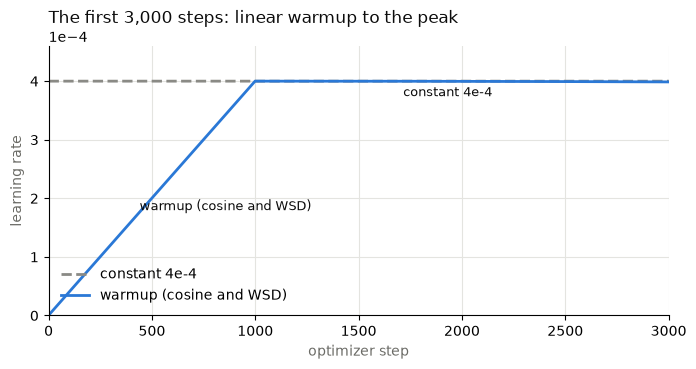

step     0: cosine 4.00e-07 | WSD 4.00e-07
step   499: cosine 2.00e-04 | WSD 2.00e-04
step   999: cosine 4.00e-04 | WSD 4.00e-04
step  1000: cosine 4.00e-04 | WSD 4.00e-04


In [4]:
cosine = curve("cosine")
wsd = curve("wsd")

fig, ax = plt.subplots(figsize=(8, 3.5))
plot_curves(
    ax,
    [
        ("constant 4e-4", [4e-4] * TOTAL_STEPS, REFERENCE, 2_200),
        ("warmup (cosine and WSD)", cosine, COLORS[0], 400),
    ],
    "The first 3,000 steps: linear warmup to the peak",
    x_max=3_000,
)
plt.show()

for step in (0, 499, 999, 1_000):
    print(f"step {step:>5}: cosine {cosine[step]:.2e} | WSD {wsd[step]:.2e}")

## 2. The cosine schedule

After the warmup, the learning rate decreases along **half a cosine wave**:
from the peak, right after the warmup, to the minimum, at the last step.

```text
progress = (step - warmup_steps) / (total_steps - 1 - warmup_steps)  # 0 .. 1
lr = min_lr + (peak_lr - min_lr) * 0.5 * (1 + cos(pi * progress))
```

The shape is gentle at both ends: the learning rate stays near the peak for a
while, decreases fastest in the middle, and flattens out near the minimum.

Why decrease it at all? Large steps make fast progress, but near a good
solution they "bounce" around it, because each batch pulls the weights in a
slightly different direction. Small steps at the end average out that noise
and let the model settle, which usually gives a lower final loss than a
constant learning rate.

The cosine is the classic schedule, used for example by GPT-3 and in the
appendix of the book on training improvements. Its limit: **the total number
of steps must be known from the start**, because it decides the shape of the
whole curve.

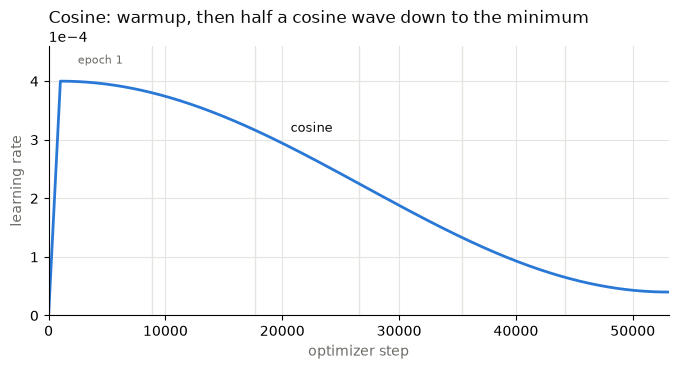

Middle of the decay, step 27,034: 2.20e-04
Last step: 4.00e-05


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
plot_curves(
    ax,
    [("cosine", cosine, COLORS[0], 20_000)],
    "Cosine: warmup, then half a cosine wave down to the minimum",
)
for epoch in range(1, NUM_EPOCHS):
    ax.axvline(epoch * STEPS_PER_EPOCH, color="#e4e4e0", linewidth=1, zorder=0)
ax.text(STEPS_PER_EPOCH / 2, 4.3e-4, "epoch 1", color=MUTED, fontsize=8, ha="center")
plt.show()

middle = 1_000 + (TOTAL_STEPS - 1 - 1_000) // 2
print(f"Middle of the decay, step {middle:,}: {cosine[middle]:.2e}")
print(f"Last step: {cosine[-1]:.2e}")

The thin vertical lines mark the end of each epoch. In the middle of
the decay the learning rate is half way between the peak and the minimum,
2.2e-4.

## 3. The WSD schedule: warmup, stable, decay

WSD splits the training in three phases:

1. **warmup**, as before;
2. **stable**: the learning rate stays at the peak for most of the training;
3. **decay**: only in the last part, `decay_fraction` of the steps, it
   decreases **linearly** to the minimum.

The idea is that most of the learning happens at a high learning rate, and a
relatively short decay at the end is enough to settle the model. Recent work,
such as the MiniCPM models (2024) and Hägele et al. (2024), reports final
results similar to the cosine at the same number of steps.

The chart shows three values of `decay_fraction`; a dot marks where each
decay starts. The longer the decay, the earlier the learning rate starts to go
down.

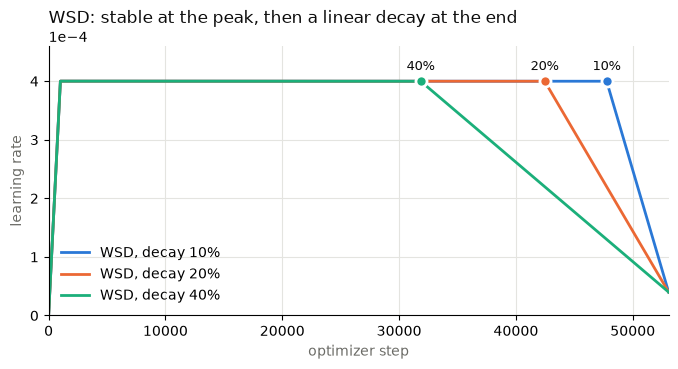

decay 10%: stable until step 47,763, then 5,307 decay steps
decay 20%: stable until step 42,456, then 10,614 decay steps
decay 40%: stable until step 31,842, then 21,228 decay steps


In [6]:
fractions = (0.1, 0.2, 0.4)
fig, ax = plt.subplots(figsize=(8, 3.5))
plot_curves(
    ax,
    [
        (
            f"WSD, decay {fraction:.0%}",
            curve("wsd", decay_fraction=fraction),
            color,
            None,
        )
        for fraction, color in zip(fractions, COLORS)
    ],
    "WSD: stable at the peak, then a linear decay at the end",
)
# Mark where each decay starts: the "knee" of the curve
for fraction, color in zip(fractions, COLORS):
    start = TOTAL_STEPS - round(fraction * TOTAL_STEPS)
    ax.plot(
        start,
        4e-4,
        "o",
        color=color,
        markersize=8,
        markeredgecolor="white",
        markeredgewidth=2,
    )
    ax.annotate(
        f"{fraction:.0%}",
        (start, 4e-4),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        color=INK,
        fontsize=9,
    )
plt.show()

for fraction in fractions:
    start = TOTAL_STEPS - round(fraction * TOTAL_STEPS)
    print(
        f"decay {fraction:.0%}: stable until step {start:,}, "
        f"then {TOTAL_STEPS - start:,} decay steps"
    )

With the default `decay_fraction = 0.2`, the learning rate stays at
4e-4 until step 42,456, near the end of epoch 5, and then decreases during
the last 10,614 steps.

## 4. Constant, cosine, and WSD together

The three curves have the same peak and the same number of steps. They differ
in **how much of the training runs at a high learning rate**:

* **constant**: all of it, and there is no final settling;
* **cosine**: it starts to decrease right after the warmup;
* **WSD**: it stays high until the final decay, then catches up quickly.

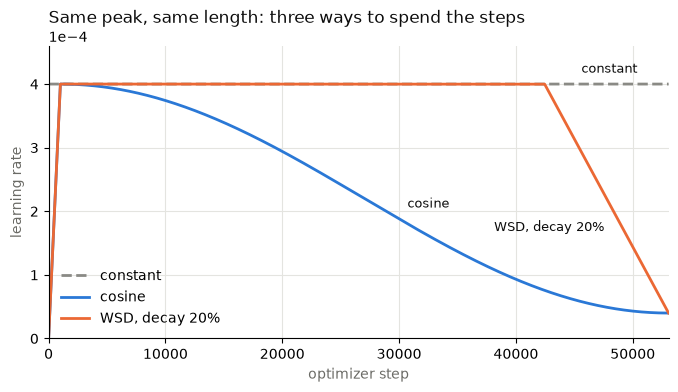

   step   epoch   constant     cosine        WSD
      0    0.00   4.00e-04   4.00e-07   4.00e-07
    999    0.11   4.00e-04   4.00e-04   4.00e-04
  8,844    1.00   4.00e-04   3.80e-04   4.00e-04
 17,689    2.00   4.00e-04   3.16e-04   4.00e-04
 26,534    3.00   4.00e-04   2.25e-04   4.00e-04
 35,379    4.00   4.00e-04   1.33e-04   4.00e-04
 44,224    5.00   4.00e-04   6.50e-05   3.40e-04
 53,069    6.00   4.00e-04   4.00e-05   4.00e-05


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
plot_curves(
    ax,
    [
        ("constant", [4e-4] * TOTAL_STEPS, REFERENCE, 48_000, "above"),
        ("cosine", cosine, COLORS[0], 30_000),
        ("WSD, decay 20%", wsd, COLORS[1], 48_500),
    ],
    "Same peak, same length: three ways to spend the steps",
)
plt.show()

# A table of the same values: the chart in numbers
print(f"{'step':>7}  {'epoch':>6}  {'constant':>9}  {'cosine':>9}  {'WSD':>9}")
for step in (0, 999, 8_844, 17_689, 26_534, 35_379, 44_224, 53_069):
    epoch = step / STEPS_PER_EPOCH
    print(
        f"{step:>7,}  {epoch:>6.2f}  {4e-4:>9.2e}  "
        f"{cosine[step]:>9.2e}  {wsd[step]:>9.2e}"
    )

A useful number to compare them is the **average learning rate**: how
much total "movement" each schedule allows. WSD keeps more of it than the
cosine, while still ending at the same minimum.

In [8]:
for name, values in (
    ("constant", [4e-4] * TOTAL_STEPS),
    ("cosine", cosine),
    ("WSD", wsd),
):
    average = sum(values) / len(values)
    print(f"{name:<9} average learning rate {average:.2e}")

constant  average learning rate 4.00e-04
cosine    average learning rate 2.20e-04
WSD       average learning rate 3.60e-04


## 5. Extending a run

Suppose that, after starting a 6-epoch run, we decide to train for 8 epochs:
70,760 steps instead of 53,070. What happens to the learning rates of the
steps **already done**?

* **Cosine**: the shape depends on the total number of steps, so the whole
  curve changes. The first steps of the 8-epoch curve are higher than those
  of the 6-epoch curve: the steps already done followed a different
  schedule, and simply continuing would give a curve with a jump.
* **WSD**: during the stable phase the learning rate is the peak whatever the
  total, so the two curves are **identical** until the shorter run starts to
  decay. As long as the decay has not started, the run can be extended.

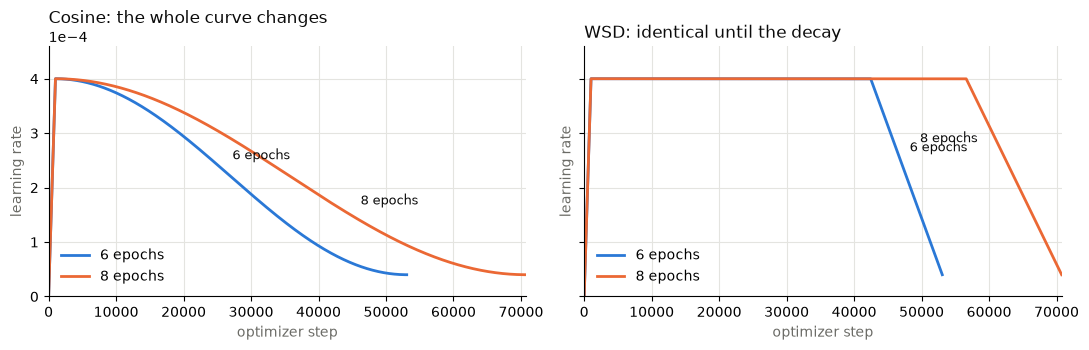

Step 17,689 (end of epoch 2):
  cosine: 6 epochs 3.162e-04 | 8 epochs 3.515e-04
  WSD:    6 epochs 4.000e-04 | 8 epochs 4.000e-04


In [9]:
longer = 8 * STEPS_PER_EPOCH  # 70,760 steps
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
plot_curves(
    left,
    [
        ("6 epochs", cosine, COLORS[0], 26_000),
        ("8 epochs", curve("cosine", total_steps=longer), COLORS[1], 45_000),
    ],
    "Cosine: the whole curve changes",
    x_max=longer,
)
plot_curves(
    right,
    [
        ("6 epochs", wsd, COLORS[0], 47_000),
        ("8 epochs", curve("wsd", total_steps=longer), COLORS[1], 60_000),
    ],
    "WSD: identical until the decay",
    x_max=longer,
)
plt.tight_layout()
plt.show()

cosine_8 = curve("cosine", total_steps=longer)
wsd_8 = curve("wsd", total_steps=longer)
step = 2 * STEPS_PER_EPOCH - 1  # Last step of epoch 2
print(f"Step {step:,} (end of epoch 2):")
print(f"  cosine: 6 epochs {cosine[step]:.3e} | 8 epochs {cosine_8[step]:.3e}")
print(f"  WSD:    6 epochs {wsd[step]:.3e} | 8 epochs {wsd_8[step]:.3e}")

## 6. Schedules and checkpoints

Our training can stop and resume from a checkpoint saved at the end of each
epoch. Does the schedule survive a restart? Yes, because
`learning_rate(step, ...)` is a **pure function** of the optimizer step: it
has no internal state. The checkpoint already stores the step number, so a
resumed run computes exactly the same learning rates as an uninterrupted one.

PyTorch also has scheduler objects (`torch.optim.lr_scheduler`), which keep a
counter inside and must be saved and restored with the checkpoint. A pure
function avoids that extra state, and with it a class of bugs.

The learning rate is written into the optimizer before each step with
`set_learning_rate`. This also overrides the value that
`optimizer.load_state_dict` restores from a checkpoint, so the schedule, not
an old saved value, always decides. A tiny example:

In [10]:
weight = torch.nn.Parameter(torch.ones(3))
optimizer = torch.optim.AdamW([weight], lr=4e-4)

# Pretend we resume after epoch 2: the next step has index 17,690
resume_step = 2 * STEPS_PER_EPOCH
value = learning_rate(resume_step, schedule="wsd", **SCHEDULE)
set_learning_rate(optimizer, value)

print(f"Step {resume_step:,} after the restart: {optimizer.param_groups[0]['lr']:.2e}")
print(f"Same step, uninterrupted run:      {wsd[resume_step]:.2e}")

Step 17,690 after the restart: 4.00e-04
Same step, uninterrupted run:      4.00e-04


## Summary

| | Constant | Cosine | WSD |
| --- | --- | --- | --- |
| Warmup | no | yes | yes |
| After the warmup | always the peak | decreases from the start | peak, then a final decay |
| Final settling | no | yes | yes |
| Total steps | not needed | fixed from the start | can change until the decay |
| Extending a run | possible | changes the whole curve | possible during the stable phase |
| State to save in a checkpoint | none | none (pure function) | none (pure function) |

* The **warmup** protects the first steps, when the weights are random and the
  optimizer statistics are not reliable yet.
* A **decay** at the end lets the model settle, and usually lowers the final
  loss.
* **Cosine** is the classic choice when the length of the run is known.
* **WSD** keeps a high learning rate for longer and lets a run be extended,
  which fits long trainings on a laptop that may stop and resume.

The functions are in
[`build_llm/lr_schedule.py`](../build_llm/lr_schedule.py), with their tests in
`tests/test_lr_schedule.py`. The training script uses the cosine schedule,
with 6 epochs.